# Практическая работа № 4
## Регрессионная модель

### Цель работы
Реализовать градиентный спуск для линейной регрессии с использованием NumPy и сравнить его результаты с моделью LinearRegression из Scikit-learn.

### Задачи
1. Подготовить данные для регрессии.
2. Реализовать функцию потерь MSE и её градиент.
3. Реализовать алгоритм градиентного спуска.
4. Обучить собственную модель и модель Scikit-learn.
5. Сравнить коэффициенты и метрики качества.
6. Исследовать влияние скорости обучения.
7. Построить графики и сформулировать выводы.

### Используемые библиотеки
NumPy, Pandas, Matplotlib, Scikit-learn.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [29]:
np.random.seed(42)

n = 200

area = np.random.randint(30, 200, n)
rooms = np.random.randint(1, 6, n)
age = np.random.randint(0, 40, n)

price = (
    area * 5000
    + rooms * 15000
    - age * 2000
    + np.random.normal(0, 20000, n)
)

df = pd.DataFrame({
    "area": area,
    "rooms": rooms,
    "age": age,
    "price": price
})

df.head()

,area,rooms,age,price
0,132,4,25,667134.334826
1,122,2,15,597987.906375
2,44,3,36,186836.440935
3,136,1,21,638251.410670
4,101,1,28,473254.486273


In [30]:
X = df[["area", "rooms", "age"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (160, 3)
Test: (40, 3)


In [31]:
def compute_mse(X, y, weights, bias):
    predictions = X @ weights + bias
    return np.mean((predictions - y) ** 2)


def compute_gradients(X, y, weights, bias):
    n = len(y)
    predictions = X @ weights + bias
    errors = predictions - y

    grad_weights = (2 / n) * (X.T @ errors)
    grad_bias = (2 / n) * np.sum(errors)

    return grad_weights, grad_bias

In [32]:
def gradient_descent(X, y, learning_rate=0.01, iterations=3000):
    weights = np.zeros(X.shape[1])
    bias = 0.0
    losses = []

    for _ in range(iterations):
        grad_weights, grad_bias = compute_gradients(
            X, y, weights, bias
        )

        weights -= learning_rate * grad_weights
        bias -= learning_rate * grad_bias

        losses.append(compute_mse(X, y, weights, bias))

    return weights, bias, losses

In [33]:
weights, bias, losses = gradient_descent(
    X_train_scaled,
    y_train.to_numpy(),
    learning_rate=0.01,
    iterations=3000
)

print("Коэффициенты:", weights)
print("Свободный член:", bias)
print("Последний MSE:", losses[-1])

Коэффициенты: [236143.93777845  18156.50938527 -21669.98204638]
Свободный член: 572070.0807553765
Последний MSE: 402696336.07682955


In [34]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Коэффициенты Scikit-learn:", model.coef_)
print("Свободный член Scikit-learn:", model.intercept_)

Коэффициенты Scikit-learn: [236143.93777845  18156.50938527 -21669.98204638]
Свободный член Scikit-learn: 572070.0807553793


In [35]:
y_pred_gd = X_test_scaled @ weights + bias
y_pred_sklearn = model.predict(X_test_scaled)


def evaluate_model(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n{name}")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²: {r2:.4f}")


evaluate_model(y_test, y_pred_gd, "Градиентный спуск")
evaluate_model(y_test, y_pred_sklearn, "Scikit-learn")


Градиентный спуск
MAE: 16003.16
RMSE: 19881.69
R²: 0.9941

Scikit-learn
MAE: 16003.16
RMSE: 19881.69
R²: 0.9941


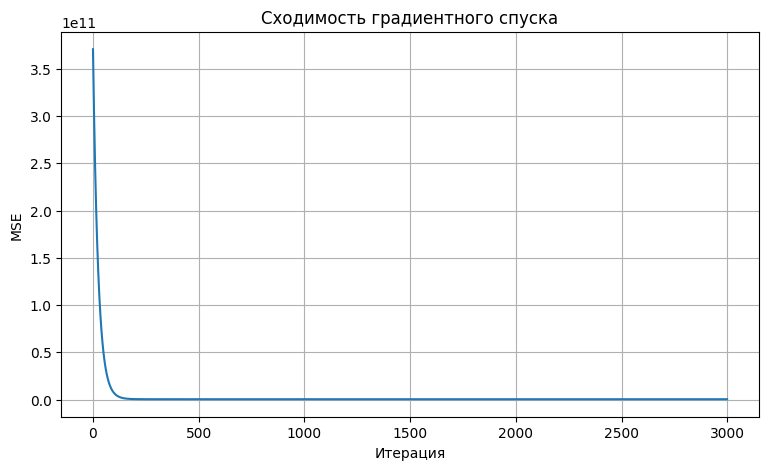

In [36]:
plt.figure(figsize=(9, 5))
plt.plot(losses)
plt.xlabel("Итерация")
plt.ylabel("MSE")
plt.title("Сходимость градиентного спуска")
plt.grid(True)
plt.show()

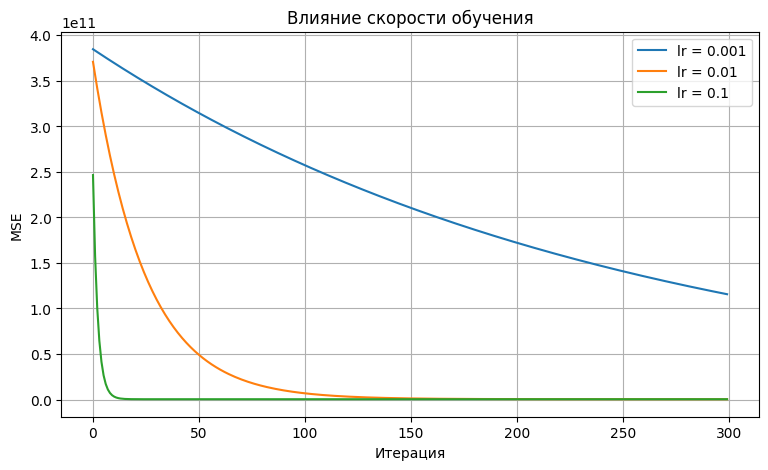

In [37]:
learning_rates = [0.001, 0.01, 0.1]
losses_by_rate = {}

for lr in learning_rates:
    _, _, rate_losses = gradient_descent(
        X_train_scaled,
        y_train.to_numpy(),
        learning_rate=lr,
        iterations=300
    )
    losses_by_rate[lr] = rate_losses

plt.figure(figsize=(9, 5))

for lr, rate_losses in losses_by_rate.items():
    plt.plot(rate_losses, label=f"lr = {lr}")

plt.xlabel("Итерация")
plt.ylabel("MSE")
plt.title("Влияние скорости обучения")
plt.legend()
plt.grid(True)
plt.show()

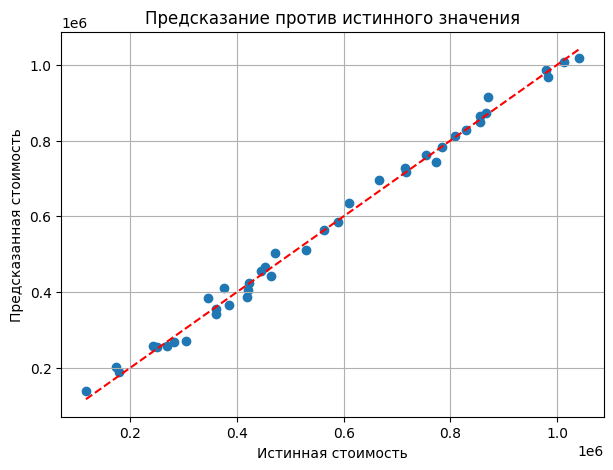

In [38]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_gd)

min_value = min(y_test.min(), y_pred_gd.min())
max_value = max(y_test.max(), y_pred_gd.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

plt.xlabel("Истинная стоимость")
plt.ylabel("Предсказанная стоимость")
plt.title("Предсказание против истинного значения")
plt.grid(True)
plt.show()

In [39]:
regression_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

regression_pipeline.fit(X_train, y_train)

y_pred_pipeline = regression_pipeline.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred_pipeline))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_pipeline)))
print("R²:", r2_score(y_test, y_pred_pipeline))

MAE: 16003.16219188635
RMSE: 19881.68903066494
R²: 0.9941127556740408


## Выводы

В ходе практической работы была реализована линейная регрессия с помощью градиентного спуска на NumPy. Также была обучена модель LinearRegression из Scikit-learn.

Модели сравнивались по MAE, RMSE и R² на тестовой выборке. MAE показывает, на сколько денежных единиц в среднем ошибается модель.

Были исследованы три скорости обучения: 0.001, 0.01 и 0.1. По графику сходимости можно оценить, какая скорость обеспечивает более быстрое и стабильное уменьшение функции потерь.

Сравнение коэффициентов и метрик позволяет проверить, насколько собственная реализация градиентного спуска близка к результатам Scikit-learn.